# Phase 1: MRI Dataset Verification & Quality Audit
**Project**: ClinIQ — AI-Powered Online Clinic  
**Module**: Computer Vision (Brain MRI Classification)  
**Target Dataset**: Brain Tumor MRI Dataset (`masoudnickparvar`)  
**Expected Classes**: `glioma`, `meningioma`, `notumor`, `pituitary`  

---

### Phase 1 Objectives & Methodology
Before building models or claiming high accuracy, we independently audit the raw dataset. In medical imaging, naive benchmarks frequently report >99% test accuracy due to **data leakage**, **cross-split duplicates**, and **shortcut learning**.

This notebook performs a comprehensive audit:
1. **Provenance & Licensing**: Document source datasets and known labeling caveats.
2. **Structural Verification**: Confirm folder layout and class counts across `Training/` and `Testing/`.
3. **Data Integrity**: Validate file readability and catch corrupted images.
4. **Per-Class Properties & Shortcut Learning Check**: Detect whether specific classes (e.g. `notumor`) have distinct resolutions or margin signatures.
5. **Exact Duplicates & Label Conflicts**: SHA-256 byte hashing to detect internal duplicates, cross-split leaks, and identical images with conflicting labels.
6. **Perceptual Near-Duplicates**: Vectorized 64-bit dHash Hamming-distance search ($D \le 10$) with visual inspection of candidate pairs.
7. **Patient-Level Leakage Assessment**: Verify whether patient identifiers exist.
8. **Dynamic, Evidence-Based Audit Verdict**: Generate an audit report driven entirely by empirical findings.


### 1. Dataset Provenance, Licensing, & Known Source Caveats

The dataset compiled by Masoud Nickparvar (`masoudnickparvar/brain-tumor-mri-dataset` on Kaggle) is an aggregation of three distinct public collections:

1. **Jun Cheng Figshare Dataset (2017)**:
   * *Source*: T1-weighted contrast-enhanced MRI from Nanfang Hospital & Tianjin Medical University ([DOI: 10.6084/m9.figshare.1512427.v5](https://doi.org/10.6084/m9.figshare.1512427.v5)).
   * *Content*: 3,064 slices across 233 patients (Glioma: 1,426, Meningioma: 708, Pituitary: 930).
   * *License*: CC BY 4.0.
   * *Note*: Contains explicit patient IDs in the original `.mat` release, but IDs were stripped when merged into flat image folders.
2. **Sartaj Bhuvaji Dataset (2020)**:
   * *Source*: Kaggle compilation from web searches, Cheng Figshare, and public hospital sites.
   * *Content*: 3,264 images across 4 classes (`glioma_tumor`, `meningioma_tumor`, `no_tumor`, `pituitary_tumor`).
   * *License*: Published under CC0 / Public Domain dedication on Kaggle.
   * *Caveat*: Medical imaging literature and community audits have flagged label ambiguity and occasional misclassifications in web-scraped images within this collection.
3. **Br35H: Brain Tumor Detection (2020)**:
   * *Source*: Kaggle compilation by Ahmed Hamada.
   * *Content*: 2,550 images (1,275 tumor, 1,275 no tumor).
   * *License*: CC0: Public Domain.
   * *Caveat*: Sourced from different scanner protocols; often used as the primary source for the `notumor` class.

**Key Engineering Implication**: Because the dataset merges distinct sources, differences in image acquisition (scanner field strength, contrast agents, black border framing) risk becoming confounding "shortcuts" that a CNN can exploit rather than learning genuine brain pathology.


In [1]:
import os
import sys
import hashlib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


In [2]:
# Dynamically resolve project root (works from /notebooks or project root)
notebook_path = Path.cwd().resolve()
if notebook_path.name == "notebooks":
    PROJECT_ROOT = notebook_path.parent
elif (notebook_path / "notebooks").exists():
    PROJECT_ROOT = notebook_path
else:
    PROJECT_ROOT = notebook_path

# Data directory
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "mri"

# Results directories
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INVENTORY_CSV_PATH = METRICS_DIR / "mri_image_inventory.csv"
REPORT_TXT_PATH = METRICS_DIR / "mri_phase1_audit_report.txt"

print(f"[*] Project Root        : {PROJECT_ROOT}")
print(f"[*] Raw MRI Data Dir    : {DATA_DIR}")
print(f"[*] Inventory CSV Path  : {INVENTORY_CSV_PATH}")
print(f"[*] Audit Report Path   : {REPORT_TXT_PATH}")


[*] Project Root        : C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv
[*] Raw MRI Data Dir    : C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv\data\raw\mri
[*] Inventory CSV Path  : C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv\results\metrics\mri_image_inventory.csv
[*] Audit Report Path   : C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv\results\metrics\mri_phase1_audit_report.txt


In [3]:
EXPECTED_SPLITS = ["Training", "Testing"]
EXPECTED_CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

assert DATA_DIR.exists(), (
    f"Error: Dataset directory not found at {DATA_DIR}.\n"
    f"Please download the dataset and place it under graduation-cv/data/raw/mri/"
)

structure_ok = True
for split in EXPECTED_SPLITS:
    split_path = DATA_DIR / split
    if not split_path.exists():
        print(f"[!] Missing split directory: {split_path}")
        structure_ok = False
    else:
        for cls in EXPECTED_CLASSES:
            cls_path = split_path / cls
            if not cls_path.exists():
                print(f"[!] Missing class directory: {cls_path}")
                structure_ok = False

if structure_ok:
    print("[+] Directory structure matches expected format (Training/Testing with 4 classes).")
else:
    print("[!] Warning: Missing components detected in data/raw/mri/. Check paths above.")


[+] Directory structure matches expected format (Training/Testing with 4 classes).


In [4]:
# Precomputed 256-element byte popcount lookup table for vectorized bit counting
POPCOUNT_TABLE = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def compute_sha256(filepath: Path) -> str:
    """Computes SHA-256 cryptographic checksum of an image file."""
    hasher = hashlib.sha256()
    with open(filepath, "rb") as f:
        while chunk := f.read(65536):
            hasher.update(chunk)
    return hasher.hexdigest()

def compute_dhash_hex(img: Image.Image, hash_size: int = 8) -> str:
    """
    Computes 64-bit Difference Hash (dHash) as a 16-character hexadecimal string.
    Stored as hex string to avoid float conversion or NaN corruption.
    """
    try:
        # Resize to (hash_size + 1, hash_size) in grayscale
        resized = img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.BILINEAR)
        pixels = np.array(resized, dtype=np.int32)
        # Gradient along width: pixel[x+1] > pixel[x]
        diff = pixels[:, 1:] > pixels[:, :-1]
        val = 0
        for bit in diff.flatten():
            val = (val << 1) | int(bit)
        return f"{val:016x}"
    except Exception:
        return None

def hex_to_uint64(hex_str: str) -> np.uint64:
    """Converts 16-char hex string to np.uint64 integer."""
    try:
        return np.uint64(int(hex_str, 16))
    except Exception:
        return np.uint64(0)

def compute_vectorized_hamming(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """
    Vectorized pairwise Hamming distance between uint64 hash arrays A (shape N) and B (shape M).
    Returns integer distance matrix of shape (N, M) with values in [0, 64].
    """
    # Bitwise XOR broadcasts to shape (N, M)
    x = A[:, None] ^ B[None, :]
    # View as 8 separate bytes and sum popcounts via lookup table
    return POPCOUNT_TABLE[x.view(np.uint8).reshape(x.shape[0], x.shape[1], 8)].sum(-1)


In [5]:
records = []
corrupted_files = []

for split in EXPECTED_SPLITS:
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        continue
        
    for class_folder in sorted(split_dir.iterdir()):
        if not class_folder.is_dir():
            continue
        class_name = class_folder.name.lower()
        
        for file_path in sorted(class_folder.iterdir()):
            if not file_path.is_file():
                continue
                
            try:
                # 1. Structural verification
                with Image.open(file_path) as img:
                    img.verify()
                
                # 2. Reopen to load pixel data and compute properties
                with Image.open(file_path) as img:
                    img.load()
                    width, height = img.size
                    mode = img.mode
                    ext = file_path.suffix.lower()
                    
                    # Estimate black-margin fraction (pixels <= 10 intensity)
                    gray_arr = np.array(img.convert("L"))
                    dark_ratio = float((gray_arr <= 10).mean())
                    
                    # Hashes
                    sha = compute_sha256(file_path)
                    dh_hex = compute_dhash_hex(img)
                    
                    records.append({
                        "path": str(file_path),
                        "filename": file_path.name,
                        "split": split,
                        "class": class_name,
                        "width": width,
                        "height": height,
                        "aspect_ratio": round(width / height, 3),
                        "is_square": (width == height),
                        "mode": mode,
                        "ext": ext,
                        "dark_pixel_ratio": round(dark_ratio, 4),
                        "sha256": sha,
                        "dhash_hex": dh_hex
                    })
            except Exception as e:
                corrupted_files.append({
                    "path": str(file_path),
                    "filename": file_path.name,
                    "split": split,
                    "class": class_name,
                    "error": str(e)
                })

df_images = pd.DataFrame(records)
print(f"[+] Scan completed.")
print(f"    - Total readable images: {len(df_images)}")
print(f"    - Total corrupted files: {len(corrupted_files)}")


[+] Scan completed.
    - Total readable images: 7200
    - Total corrupted files: 0


In [6]:
# Save complete image inventory to CSV for fast re-checks without rescanning
if not df_images.empty:
    df_images.to_csv(INVENTORY_CSV_PATH, index=False)
    print(f"[+] Image inventory saved to: {INVENTORY_CSV_PATH}")
    print(f"    Columns: {list(df_images.columns)}")
else:
    print("[!] No images found to inventory.")


[+] Image inventory saved to: C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv\results\metrics\mri_image_inventory.csv
    Columns: ['path', 'filename', 'split', 'class', 'width', 'height', 'aspect_ratio', 'is_square', 'mode', 'ext', 'dark_pixel_ratio', 'sha256', 'dhash_hex']


In [7]:
print("--- 1. File Extensions per Split ---")
if not df_images.empty:
    ext_summary = df_images.groupby(["split", "ext"]).size().unstack(fill_value=0)
    display(ext_summary)
else:
    print("No images found.")

print("\n--- 2. File Corruption Audit ---")
if corrupted_files:
    print(f"[!] Found {len(corrupted_files)} corrupted / unreadable files:")
    for cf in corrupted_files:
        print(f"    - {cf['split']}/{cf['class']}/{cf['filename']}: {cf['error']}")
else:
    print("[+] All image files are structurally valid. Zero corrupted files.")


--- 1. File Extensions per Split ---


ext,.jpg
split,
Testing,1600
Training,5600



--- 2. File Corruption Audit ---
[+] All image files are structurally valid. Zero corrupted files.


In [8]:
if not df_images.empty:
    widths = df_images["width"]
    heights = df_images["height"]
    square_count = df_images["is_square"].sum()
    non_square_count = len(df_images) - square_count

    print("--- Dimension Statistics ---")
    print(f"Width   : min = {widths.min()}, max = {widths.max()}, median = {widths.median():.0f}, mean = {widths.mean():.1f}")
    print(f"Height  : min = {heights.min()}, max = {heights.max()}, median = {heights.median():.0f}, mean = {heights.mean():.1f}")
    print(f"Square images     : {square_count} ({square_count / len(df_images) * 100:.2f}%)")
    print(f"Non-square images : {non_square_count} ({non_square_count / len(df_images) * 100:.2f}%)")

    print("\n--- Top 10 Most Common Dimensions (Width x Height) ---")
    df_images["size_str"] = df_images["width"].astype(str) + "x" + df_images["height"].astype(str)
    dim_counts = df_images["size_str"].value_counts().head(10).reset_index()
    dim_counts.columns = ["Dimensions", "Count"]
    dim_counts["Percentage"] = (dim_counts["Count"] / len(df_images) * 100).round(2)
    display(dim_counts)


--- Dimension Statistics ---
Width   : min = 150, max = 1375, median = 512, mean = 453.3
Height  : min = 167, max = 1446, median = 512, mean = 456.9
Square images     : 5667 (78.71%)
Non-square images : 1533 (21.29%)

--- Top 10 Most Common Dimensions (Width x Height) ---


,Dimensions,Count,Percentage
0,512x512,5014,69.64
1,225x225,338,4.69
2,630x630,90,1.25
3,201x251,57,0.79
4,228x221,51,0.71
5,232x217,50,0.69
6,442x442,48,0.67
7,236x236,48,0.67
8,150x198,44,0.61
9,200x252,43,0.60


In [9]:
print("--- Per-Class Resolution & Shortcut Analysis ---")
print("We check whether resolution or background margin correlates with class (source-shortcut risk):\n")

if not df_images.empty:
    for c in sorted(df_images["class"].unique()):
        s = df_images[df_images["class"] == c]
        top_sizes = dict(s["size_str"].value_counts(normalize=True).head(4).mul(100).round(1))
        avg_dark = s["dark_pixel_ratio"].mean() * 100
        print(f"Class: {c:<12}")
        print(f"  - Top resolutions (%): {top_sizes}")
        print(f"  - Distinct resolutions: {s['size_str'].nunique()}")
        print(f"  - Mean dark background ratio: {avg_dark:.1f}%")
        print()


--- Per-Class Resolution & Shortcut Analysis ---
We check whether resolution or background margin correlates with class (source-shortcut risk):

Class: glioma      
  - Top resolutions (%): {'512x512': np.float64(95.8), '236x236': np.float64(0.3), '524x581': np.float64(0.2), '200x249': np.float64(0.1)}
  - Distinct resolutions: 62
  - Mean dark background ratio: 50.7%

Class: meningioma  
  - Top resolutions (%): {'512x512': np.float64(86.1), '225x225': np.float64(0.8), '442x442': np.float64(0.4), '455x500': np.float64(0.3)}
  - Distinct resolutions: 126
  - Mean dark background ratio: 46.3%

Class: notumor     
  - Top resolutions (%): {'225x225': np.float64(17.6), '630x630': np.float64(5.0), '201x251': np.float64(2.9), '232x217': np.float64(2.8)}
  - Distinct resolutions: 250
  - Mean dark background ratio: 34.6%

Class: pituitary   
  - Top resolutions (%): {'512x512': np.float64(95.6), '256x256': np.float64(1.6), '225x225': np.float64(0.3), '201x210': np.float64(0.2)}
  - Distinct 

In [10]:
print("--- Image Color Modes per Split ---")
if not df_images.empty:
    mode_summary = df_images.groupby(["split", "mode"]).size().unstack(fill_value=0)
    display(mode_summary)
    
    unique_modes = list(df_images["mode"].unique())
    print(f"\nUnique modes observed: {unique_modes}")
    if set(unique_modes) == {"RGB"}:
        print("-> All images stored as RGB (3 channels). Standard loading pipeline applies.")
    else:
        print("-> Non-RGB modes present. Explicit PIL `.convert('RGB')` is required in preprocessing.")


--- Image Color Modes per Split ---


mode,L,P,RGB,RGBA
split,,,,
Testing,709,0,891,0
Training,2358,1,3238,3



Unique modes observed: ['L', 'RGB', 'RGBA', 'P']
-> Non-RGB modes present. Explicit PIL `.convert('RGB')` is required in preprocessing.


In [11]:
print("--- Exact Duplicates & Label Conflict Audit (SHA-256) ---\n")

if not df_images.empty:
    g = df_images.groupby("sha256")
    
    # 1. Label conflicts: same image byte content, different assigned labels
    conflict = g.filter(lambda x: x["class"].nunique() > 1)
    conflict_count = conflict["sha256"].nunique()
    
    # 2. Cross-split duplicates (Training <-> Testing leakage)
    train_sha = set(df_images.loc[df_images["split"] == "Training", "sha256"])
    test_sha = set(df_images.loc[df_images["split"] == "Testing", "sha256"])
    cross_split_leak = df_images[(df_images["split"] == "Testing") & df_images["sha256"].isin(train_sha)]
    
    # 3. Internal duplicates within each split
    dupes_in_train = df_images[df_images["split"] == "Training"].duplicated(subset=["sha256"]).sum()
    dupes_in_test = df_images[df_images["split"] == "Testing"].duplicated(subset=["sha256"]).sum()
    
    print(f"Total images scanned                   : {len(df_images)}")
    print(f"Unique SHA-256 checksums               : {df_images['sha256'].nunique()}")
    print(f"Duplicates within Training set         : {dupes_in_train}")
    print(f"Duplicates within Testing set          : {dupes_in_test}")
    print(f"Test images byte-identical to Train img: {len(cross_split_leak)}")
    print(f"Hash groups with conflicting labels    : {conflict_count}")
    
    if len(cross_split_leak) > 0:
        print(f"\n[!] LEAKAGE ALERT: {len(cross_split_leak)} test images are exact duplicates of training images.")
        print("Sample cross-split identical images:")
        for _, row in cross_split_leak.head(5).iterrows():
            # Find matching train image
            match = df_images[(df_images["split"] == "Training") & (df_images["sha256"] == row["sha256"])].iloc[0]
            print(f"    Test: {row['class']}/{row['filename']} <==> Train: {match['class']}/{match['filename']}")
            
    if conflict_count > 0:
        print(f"\n[!] CONFLICT ALERT: {conflict_count} image hashes appear under multiple different class labels.")
        for sha, grp in conflict.groupby("sha256"):
            classes_assigned = grp[["split", "class", "filename"]].to_dict(orient="records")
            print(f"    SHA {sha[:12]}... -> {classes_assigned}")
            break
else:
    conflict_count = 0
    cross_split_leak = pd.DataFrame()
    dupes_in_train = 0
    dupes_in_test = 0


--- Exact Duplicates & Label Conflict Audit (SHA-256) ---



Total images scanned                   : 7200
Unique SHA-256 checksums               : 7013
Duplicates within Training set         : 171
Duplicates within Testing set          : 16
Test images byte-identical to Train img: 0
Hash groups with conflicting labels    : 0


In [12]:
print("--- Perceptual Near-Duplicate Search (Vectorized dHash Hamming Distance) ---\n")

if not df_images.empty:
    df_images = df_images.reset_index(drop=True)
    
    # Convert hex strings to uint64 array
    H = np.array([hex_to_uint64(h) for h in df_images["dhash_hex"]], dtype=np.uint64)
    lab = df_images["class"].to_numpy()
    
    tr_idx = np.where(df_images["split"] == "Training")[0]
    te_idx = np.where(df_images["split"] == "Testing")[0]
    
    mind = np.empty(len(te_idx), dtype=int)
    nn_idx = np.empty(len(te_idx), dtype=int)
    
    # Batch compare test images against training images (256 test images at a time)
    batch_size = 256
    for s in range(0, len(te_idx), batch_size):
        end = min(s + batch_size, len(te_idx))
        sub_te = te_idx[s:end]
        D = compute_vectorized_hamming(H[sub_te], H[tr_idx])
        mind[s:end] = D.min(axis=1)
        nn_idx[s:end] = tr_idx[D.argmin(axis=1)]
    
    print(f"Evaluated {len(te_idx)} test images against all {len(tr_idx)} training images.")
    print("Hamming Distance Threshold Breakdown:")
    print("--------------------------------------------------------------------------------")
    print(f"{'Threshold (bits)':<18} | {'Test Images <= t':<18} | {'Nearest Train Label Differs':<26}")
    print("--------------------------------------------------------------------------------")
    threshold_results = {}
    for t in [0, 2, 4, 6, 8, 10]:
        m = (mind <= t)
        count_m = int(m.sum())
        diff_label = int((lab[te_idx][m] != lab[nn_idx][m]).sum())
        threshold_results[t] = (count_m, diff_label)
        print(f"Distance <= {t:<2d}       | {count_m:<18d} | {diff_label:<26d}")
    print("--------------------------------------------------------------------------------")
    print("\nNote on Distance:")
    print("  - Distance 0-2: Near-identical image/slice (consistent with same patient / slice leakage).")
    print("  - Distance 5-8: Low-frequency structural similarity; often dark MRI border collisions.")
else:
    print("No images to evaluate.")


--- Perceptual Near-Duplicate Search (Vectorized dHash Hamming Distance) ---



Evaluated 1600 test images against all 5600 training images.
Hamming Distance Threshold Breakdown:
--------------------------------------------------------------------------------
Threshold (bits)   | Test Images <= t   | Nearest Train Label Differs
--------------------------------------------------------------------------------
Distance <= 0        | 423                | 7                         
Distance <= 2        | 771                | 74                        
Distance <= 4        | 1119               | 162                       
Distance <= 6        | 1327               | 230                       
Distance <= 8        | 1476               | 282                       
Distance <= 10       | 1555               | 312                       
--------------------------------------------------------------------------------

Note on Distance:
  - Distance 0-2: Near-identical image/slice (consistent with same patient / slice leakage).
  - Distance 5-8: Low-frequency structural similar

--- Visual Inspection of Nearest-Neighbor Pairs Across Splits ---



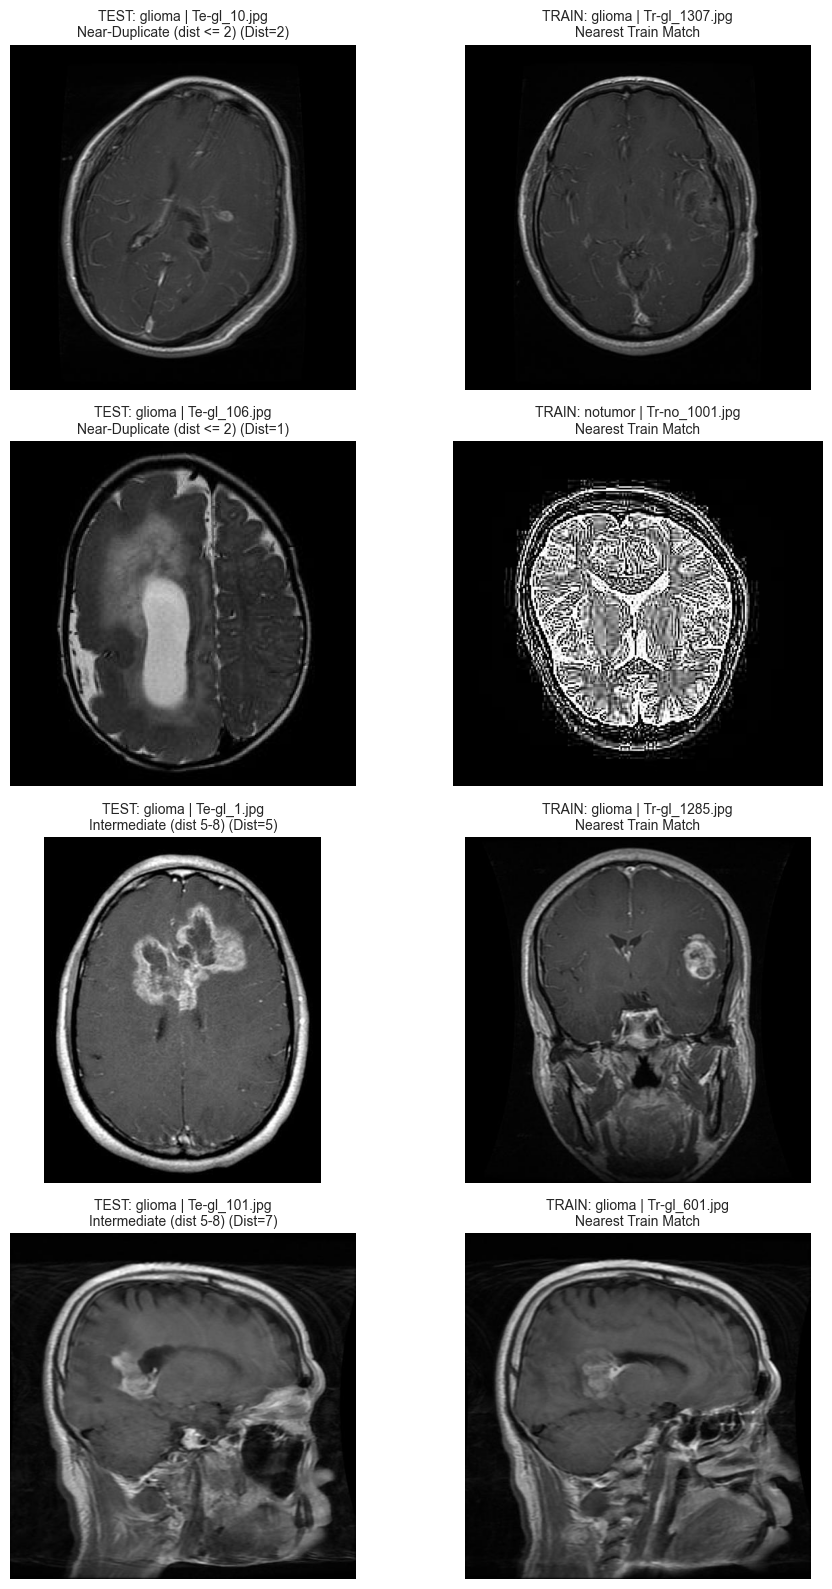

In [13]:
print("--- Visual Inspection of Nearest-Neighbor Pairs Across Splits ---\n")

if not df_images.empty and len(te_idx) > 0:
    # 1. Pairs at distance <= 2 (suspicious near-duplicates)
    close_mask = np.where(mind <= 2)[0]
    # 2. Pairs at distance 5 to 8 (intermediate similarity)
    mid_mask = np.where((mind >= 5) & (mind <= 8))[0]
    
    pairs_to_plot = []
    if len(close_mask) > 0:
        for idx in close_mask[:2]:
            pairs_to_plot.append((te_idx[idx], nn_idx[idx], mind[idx], "Near-Duplicate (dist <= 2)"))
    if len(mid_mask) > 0:
        for idx in mid_mask[:2]:
            pairs_to_plot.append((te_idx[idx], nn_idx[idx], mind[idx], "Intermediate (dist 5-8)"))
            
    if pairs_to_plot:
        fig, axes = plt.subplots(len(pairs_to_plot), 2, figsize=(10, 4 * len(pairs_to_plot)))
        if len(pairs_to_plot) == 1:
            axes = np.array([axes])
            
        for row_i, (t_idx, n_idx, dist, category) in enumerate(pairs_to_plot):
            t_row = df_images.iloc[t_idx]
            n_row = df_images.iloc[n_idx]
            
            with Image.open(t_row["path"]) as img_t:
                axes[row_i, 0].imshow(img_t.convert("RGB"))
            axes[row_i, 0].set_title(f"TEST: {t_row['class']} | {t_row['filename']}\n{category} (Dist={dist})", fontsize=10)
            axes[row_i, 0].axis('off')
            
            with Image.open(n_row["path"]) as img_n:
                axes[row_i, 1].imshow(img_n.convert("RGB"))
            axes[row_i, 1].set_title(f"TRAIN: {n_row['class']} | {n_row['filename']}\nNearest Train Match", fontsize=10)
            axes[row_i, 1].axis('off')
            
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "nearest_neighbor_pairs.png", dpi=200)
        plt.show()
    else:
        print("No pairs found within inspected distance thresholds.")


In [14]:
metadata_extensions = ["*.csv", "*.json", "*.xml", "*.txt", "*.tsv"]
meta_files = []
for ext_pattern in metadata_extensions:
    meta_files.extend(list(DATA_DIR.rglob(ext_pattern)))

print("--- Metadata Search in Dataset Directory ---")
if meta_files:
    print(f"[+] Found {len(meta_files)} metadata file(s):")
    for mf in meta_files:
        print(f"    - {mf.relative_to(DATA_DIR)}")
else:
    print("[!] No metadata files (.csv, .json, .xml, .txt) exist in the dataset directory.")
    print("    -> Technical Assessment: Patient identifiers are unavailable in this release.")
    print("    -> Formal Statement: Patient-level slice leakage cannot be ruled out because patient identifiers are unavailable.")


--- Metadata Search in Dataset Directory ---
[!] No metadata files (.csv, .json, .xml, .txt) exist in the dataset directory.
    -> Technical Assessment: Patient identifiers are unavailable in this release.
    -> Formal Statement: Patient-level slice leakage cannot be ruled out because patient identifiers are unavailable.


--- Class Counts per Split ---


class,glioma,meningioma,notumor,pituitary,Total
split,,,,,
Testing,400,400,400,400,1600
Training,1400,1400,1400,1400,5600



--- Class Percentages (%) per Split ---


class,glioma,meningioma,notumor,pituitary,Total
split,,,,,
Testing,25.0,25.0,25.0,25.0,100.0
Training,25.0,25.0,25.0,25.0,100.0


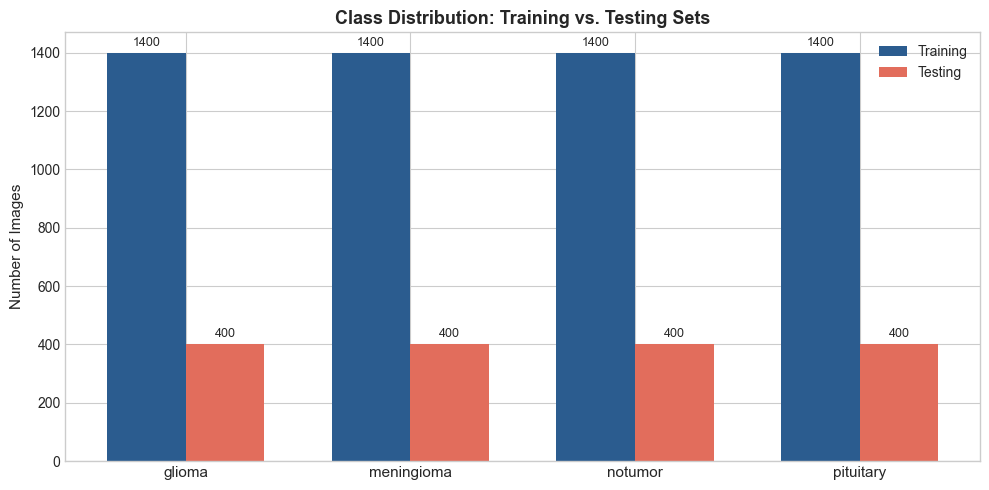

In [15]:
if not df_images.empty:
    dist_table = df_images.groupby(["split", "class"]).size().unstack(fill_value=0)
    dist_table["Total"] = dist_table.sum(axis=1)
    dist_pct = dist_table.div(dist_table["Total"], axis=0) * 100

    print("--- Class Counts per Split ---")
    display(dist_table)

    print("\n--- Class Percentages (%) per Split ---")
    display(dist_pct.round(2))

    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))
    classes = EXPECTED_CLASSES
    x = np.arange(len(classes))
    width = 0.35

    tr_counts = [df_images[(df_images["split"] == "Training") & (df_images["class"] == c)].shape[0] for c in classes]
    ts_counts = [df_images[(df_images["split"] == "Testing") & (df_images["class"] == c)].shape[0] for c in classes]

    rects1 = ax.bar(x - width/2, tr_counts, width, label='Training', color='#2b5c8f')
    rects2 = ax.bar(x + width/2, ts_counts, width, label='Testing', color='#e26d5c')

    ax.set_ylabel('Number of Images', fontsize=11)
    ax.set_title('Class Distribution: Training vs. Testing Sets', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=11)
    ax.legend()

    for rect in rects1 + rects2:
        h = rect.get_height()
        ax.annotate(f'{h}',
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=200)
    plt.show()


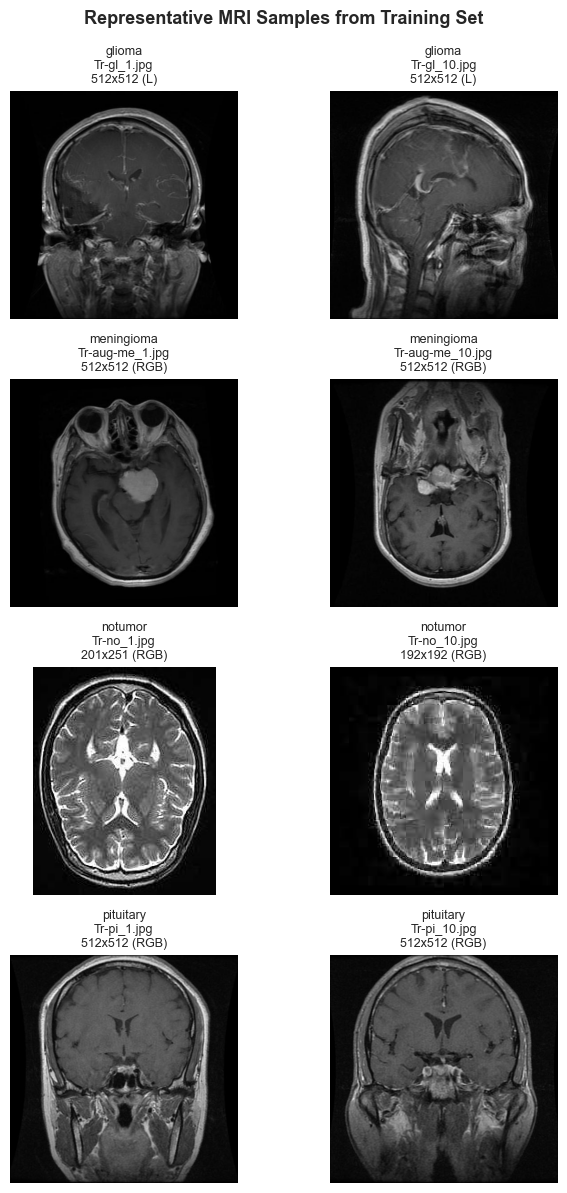

In [16]:
samples_per_class = 2
if not df_images.empty:
    fig, axes = plt.subplots(len(EXPECTED_CLASSES), samples_per_class, figsize=(7, 12))

    for row_idx, cls in enumerate(EXPECTED_CLASSES):
        cls_images = df_images[(df_images["split"] == "Training") & (df_images["class"] == cls)]
        sample_rows = cls_images.head(samples_per_class)
        
        for col_idx, (_, row) in enumerate(sample_rows.iterrows()):
            ax = axes[row_idx, col_idx]
            with Image.open(row["path"]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{cls}\n{row['filename']}\n{row['width']}x{row['height']} ({row['mode']})", fontsize=9)
            ax.axis('off')

    plt.suptitle("Representative MRI Samples from Training Set", fontsize=13, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "representative_mri_samples.png", dpi=200)
    plt.show()


In [17]:
if not df_images.empty:
    total_images = len(df_images)
    tr_total = len(df_images[df_images["split"] == "Training"])
    ts_total = len(df_images[df_images["split"] == "Testing"])

    class_counts = df_images["class"].value_counts().to_dict()
    format_counts = df_images["ext"].value_counts().to_dict()
    mode_counts = df_images["mode"].value_counts().to_dict()

    max_c = max(class_counts.values()) if class_counts else 1
    min_c = min(class_counts.values()) if class_counts else 1
    balance_ratio = max_c / min_c if min_c > 0 else 0
    balance_str = "Balanced" if balance_ratio < 1.3 else f"Imbalance detected (ratio {balance_ratio:.2f})"

    # Dynamic verdict derivation based on empirical findings
    empirical_concerns = []
    if len(cross_split_leak) > 0:
        empirical_concerns.append(f"{len(cross_split_leak)} test images are exact SHA-256 byte duplicates of training images (cross-split leakage).")
    if conflict_count > 0:
        empirical_concerns.append(f"{conflict_count} exact-byte hash groups have conflicting labels across files.")
    if threshold_results.get(2, (0, 0))[0] > 0:
        empirical_concerns.append(f"{threshold_results[2][0]} test images have Hamming distance <= 2 to a training image (consistent with near-duplicate / slice leakage).")
    if not meta_files:
        empirical_concerns.append("Patient identifiers are unavailable; patient-level slice leakage cannot be ruled out.")
    if non_square_count > 0:
        empirical_concerns.append(f"{non_square_count} non-square images present ({non_square_count/total_images*100:.1f}%).")
        
    if not empirical_concerns:
        empirical_concerns.append("None identified from automated checks.")

    # Determine data-driven verdict
    if len(cross_split_leak) > 0 or conflict_count > 0:
        verdict = "PROCEED WITH CAUTION (Significant Data Leakage / Label Noise Detected)"
        recommendation = (
            f"1. Cross-split test leakage ({len(cross_split_leak)} images) must be addressed before final evaluation.\n"
            f"2. Keep the original Testing set strictly isolated from any training or tuning.\n"
            f"3. In Phase 2, empirically test whether black-border cropping or direct resizing preserves tumor regions without distortion."
        )
    else:
        verdict = "PROCEED (No exact cross-split byte duplicates detected)"
        recommendation = (
            "1. Maintain Testing folder as an untouched final test set.\n"
            "2. Note the absence of patient IDs in project documentation as an acknowledged limitation.\n"
            "3. Test and justify margin cropping vs. direct resizing in Phase 2."
        )

    report_text = f"""MRI DATASET AUDIT
=================

Dataset path: {DATA_DIR}
Training images: {tr_total}
Testing images: {ts_total}
Total images: {total_images}

Classes:
- glioma: {class_counts.get('glioma', 0)}
- meningioma: {class_counts.get('meningioma', 0)}
- notumor: {class_counts.get('notumor', 0)}
- pituitary: {class_counts.get('pituitary', 0)}

Corrupted images: {len(corrupted_files)}

Image formats: {format_counts}

Image modes: {mode_counts}

Dimension summary:
- Width range  : {widths.min()} - {widths.max()} (median: {widths.median():.0f})
- Height range : {heights.min()} - {heights.max()} (median: {heights.median():.0f})
- Square images: {square_count} ({square_count / total_images * 100:.2f}%)
- Non-square   : {non_square_count} ({non_square_count / total_images * 100:.2f}%)

Exact duplicates:
- within training: {dupes_in_train}
- within testing: {dupes_in_test}
- train/test: {len(cross_split_leak)}
- label conflicts: {conflict_count}

Perceptual similarity findings:
- Test images with Hamming distance <= 2 to train: {threshold_results.get(2, (0, 0))[0]}
- Test images with Hamming distance <= 6 to train: {threshold_results.get(6, (0, 0))[0]}

Metadata:
- {'Available' if meta_files else 'Unavailable'}

Patient-level leakage:
- Cannot be ruled out because patient identifiers are unavailable.

Class imbalance:
- {balance_str}

Overall dataset concerns:
{chr(10).join(['- ' + c for c in empirical_concerns])}

Verdict:
- {verdict}

Recommendation for Phase 2:
{recommendation}
"""

    print(report_text)
    with open(REPORT_TXT_PATH, "w", encoding="utf-8") as f:
        f.write(report_text)
    print(f"[+] Report saved to: {REPORT_TXT_PATH}")
else:
    print("[!] Dataset is empty. Place images in data/raw/mri/ and re-run.")


MRI DATASET AUDIT

Dataset path: C:\Users\LOQ\Documents\STUDYING\4th\Graduation project\graduation-cv\data\raw\mri
Training images: 5600
Testing images: 1600
Total images: 7200

Classes:
- glioma: 1800
- meningioma: 1800
- notumor: 1800
- pituitary: 1800

Corrupted images: 0

Image formats: {'.jpg': 7200}

Image modes: {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}

Dimension summary:
- Width range  : 150 - 1375 (median: 512)
- Height range : 167 - 1446 (median: 512)
- Square images: 5667 (78.71%)
- Non-square   : 1533 (21.29%)

Exact duplicates:
- within training: 171
- within testing: 16
- train/test: 0
- label conflicts: 0

Perceptual similarity findings:
- Test images with Hamming distance <= 2 to train: 771
- Test images with Hamming distance <= 6 to train: 1327

Metadata:
- Unavailable

Patient-level leakage:
- Cannot be ruled out because patient identifiers are unavailable.

Class imbalance:
- Balanced

Overall dataset concerns:
- 771 test images have Hamming distance <= 2 to a tra